<center><h1>Guo_Haosen_HW4</h1></center>
<br>
<br>

Name: Haosen Guo
<br>
Github Username: iamevan-g
<br>
USC ID: 7183115772

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [20]:
from pathlib import Path
import re
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
warnings.filterwarnings("ignore")


Get the AReM Data Set

In [21]:
data_dir = Path("../data")
records = []

for folder in data_dir.iterdir():
    if folder.is_dir():
        for file in folder.iterdir():
            match = re.search(r"dataset(\d+)", file.stem, re.I)
            if match:
                records.append({
                    "activity": folder.name,
                    "dataset": int(match.group(1)),
                    "file_path": file
                })

arem_files = pd.DataFrame(records).sort_values(["activity", "dataset"]).reset_index(drop=True)


### (b) Splitting Data

In [22]:
arem_files["split"] = arem_files.apply(
    lambda row: "test" if row["dataset"] <= (
        2 if row["activity"].lower() in {"bending1", "bending2"} else 3
    ) else "train",
    axis=1
)

test_files = arem_files[arem_files["split"] == "test"].reset_index(drop=True)
train_files = arem_files[arem_files["split"] == "train"].reset_index(drop=True)

print("Total:", len(arem_files))
print("Train:", len(train_files))
print("Test:", len(test_files))

y_train = train_files["activity"].str.startswith("bending").astype(int).to_numpy()
y_test = test_files["activity"].str.startswith("bending").astype(int).to_numpy()

Total: 88
Train: 69
Test: 19


### (c) Feature Extraction

In [23]:
stats = ["min", "max", "mean", "median", "std", "1st quart", "3rd quart"]
describe_keys = ["min", "max", "mean", "50%", "std", "25%", "75%"]
series = {path: pd.read_csv(path, header=None, comment="#", sep=r"[,\s]+", engine="python",
                            names=range(8)).iloc[:, 1:7].to_numpy()
          for path in arem_files["file_path"]}

def extract_features(files, l=1):
    rows = []
    for path in files["file_path"]:
        row = {}
        for i, column in enumerate(series[path].T, start=1):
            for s, segment in enumerate(np.array_split(column, l), start=1):
                suffix = f"_{s}" if l > 1 else ""
                features = pd.Series(segment).describe()[describe_keys]
                row.update({f"{stat}{i}{suffix}": value for stat, value in zip(stats, features)})
        rows.append(row)
    return pd.DataFrame(rows, index=files.index)

feature_data = extract_features(arem_files)
feature_data.index = pd.RangeIndex(1, len(feature_data) + 1, name="Instance")
feature_data


,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,...,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
Instance,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

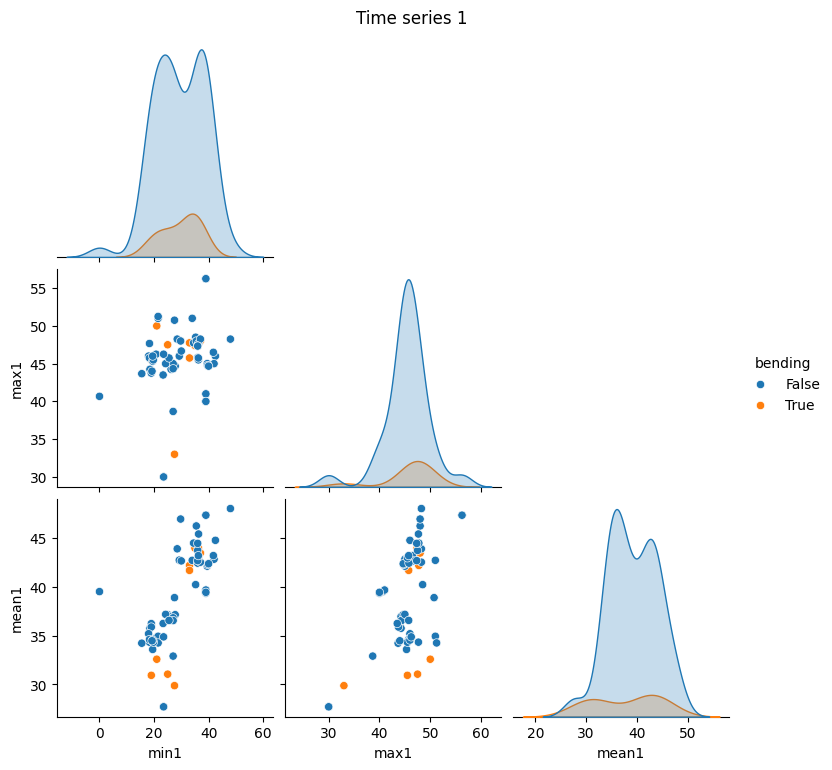

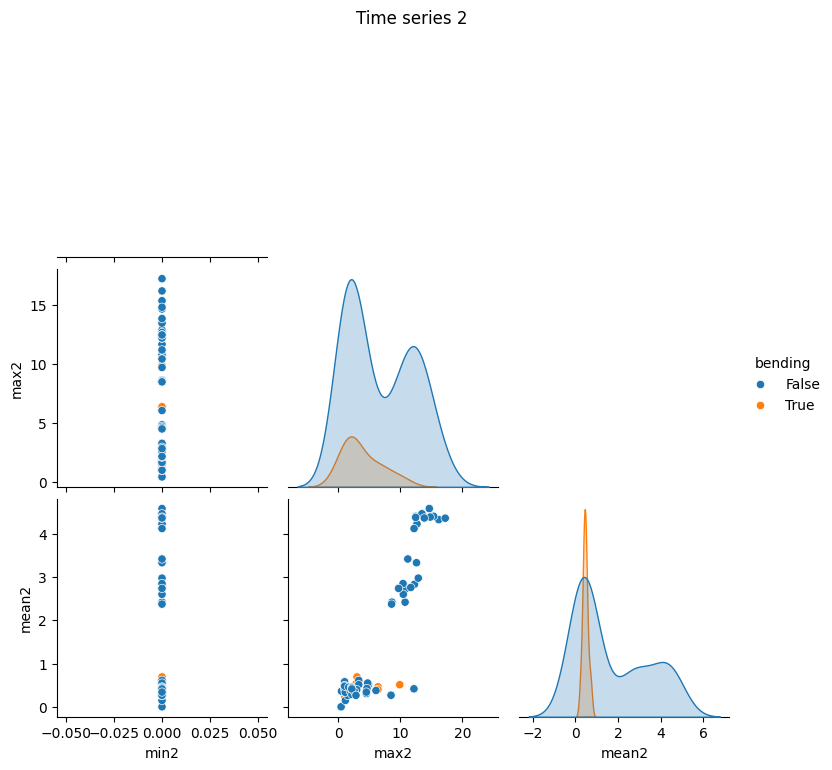

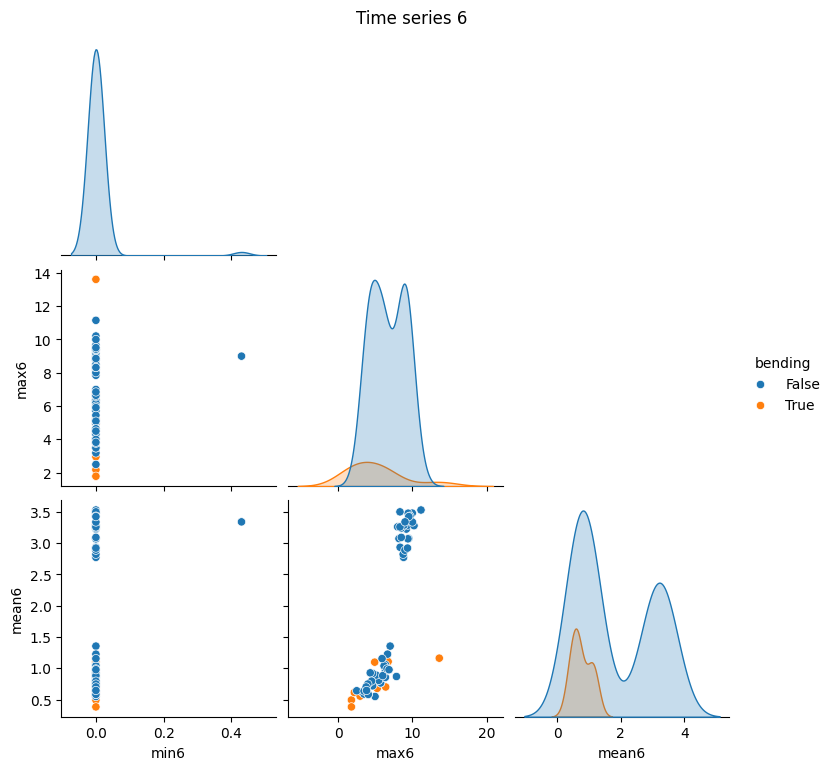

In [24]:
X1 = extract_features(train_files)
for i in (1, 2, 6):
    g = sns.pairplot(X1[[f"{s}{i}" for s in ("min", "max", "mean")]].assign(bending=y_train == 1),
                     hue="bending", corner=True, height=2.5)
    g.figure.suptitle(f"Time series {i}", y=1.02)
plt.show()


#### ii. Splitted Plots

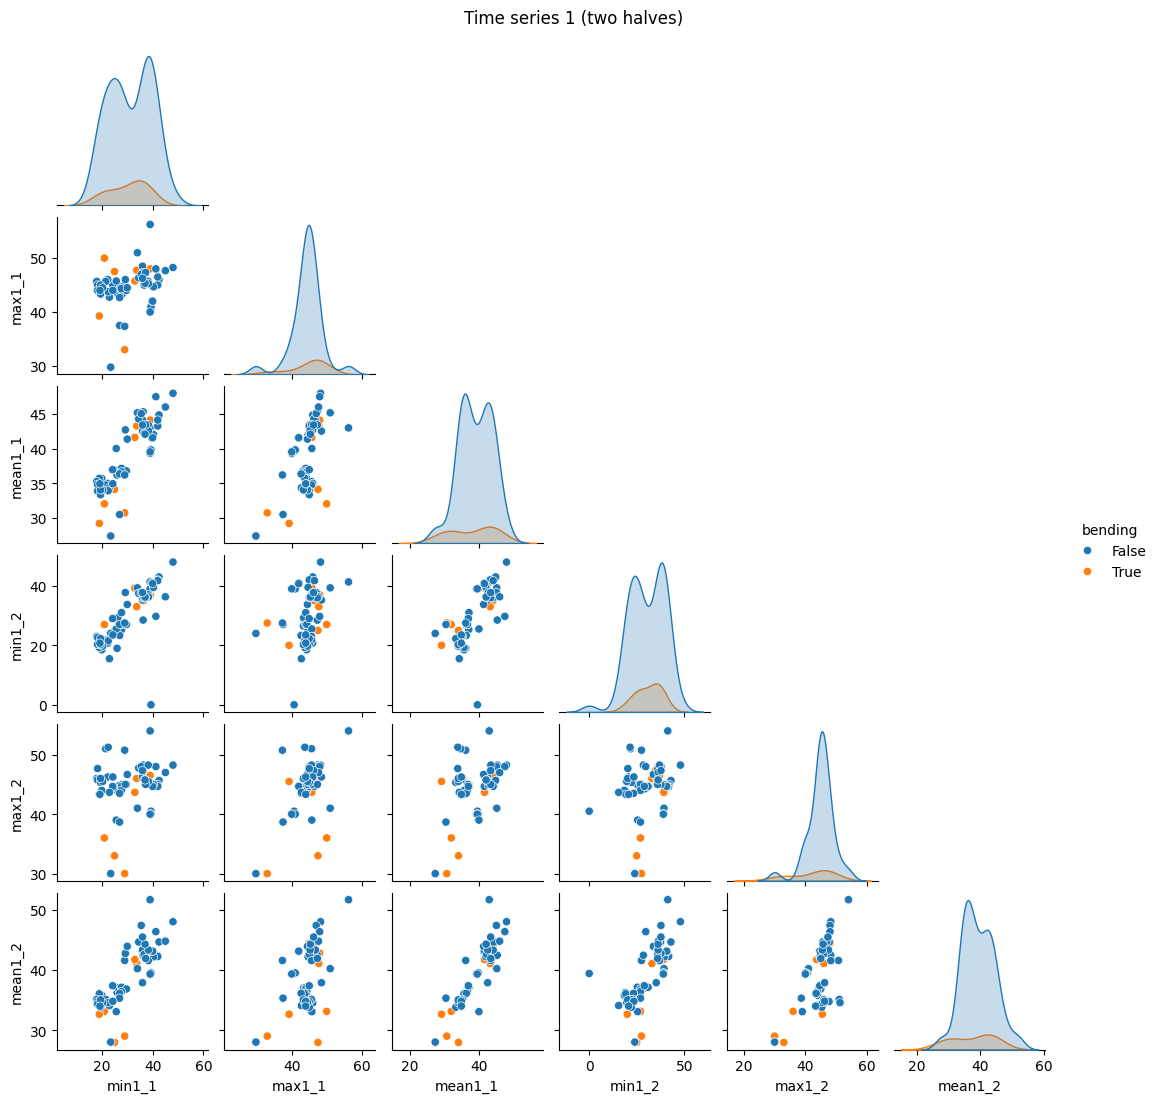

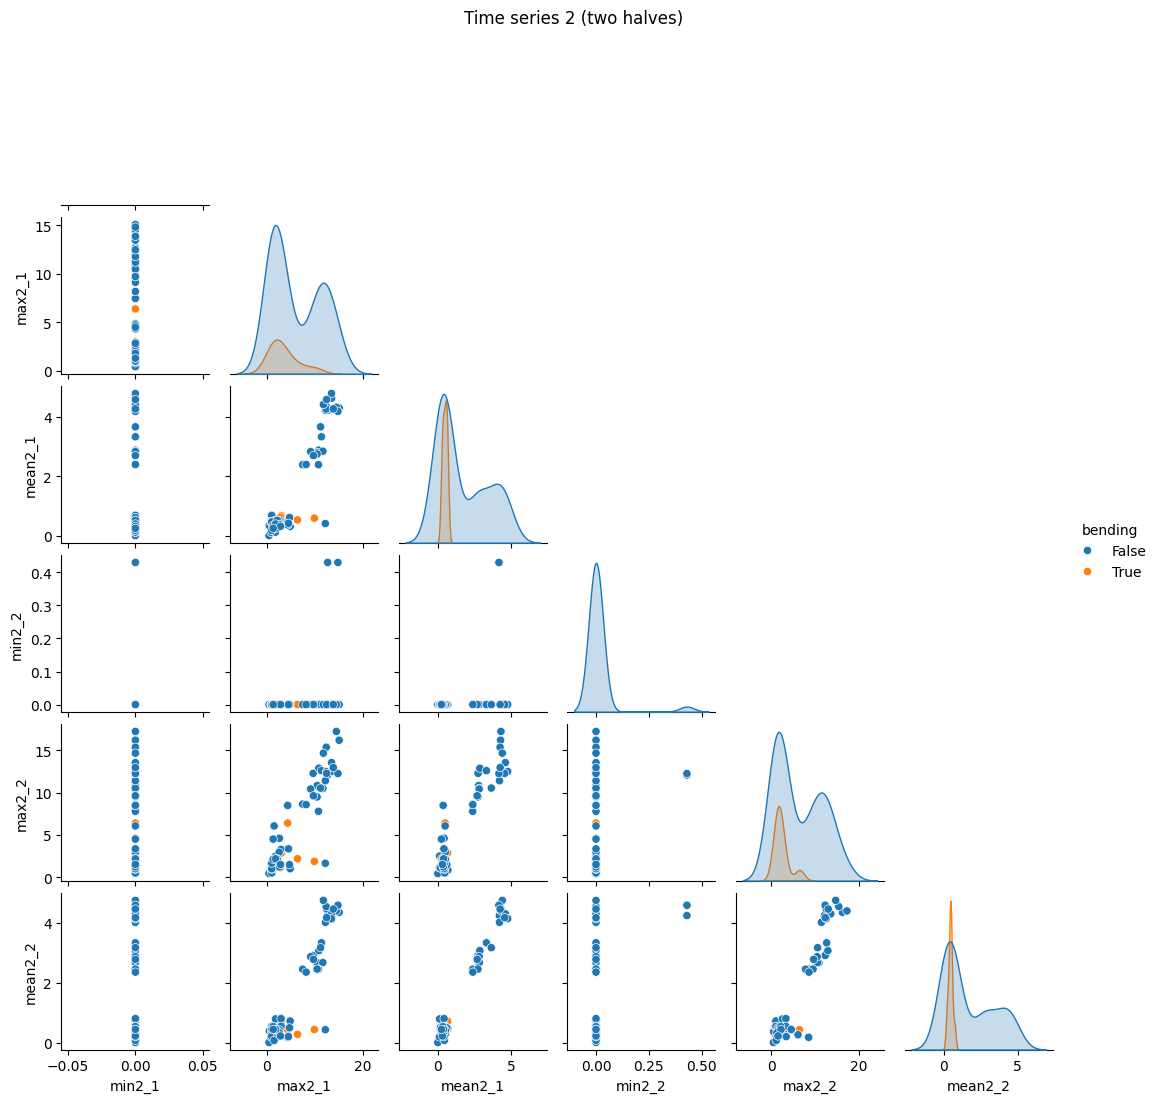

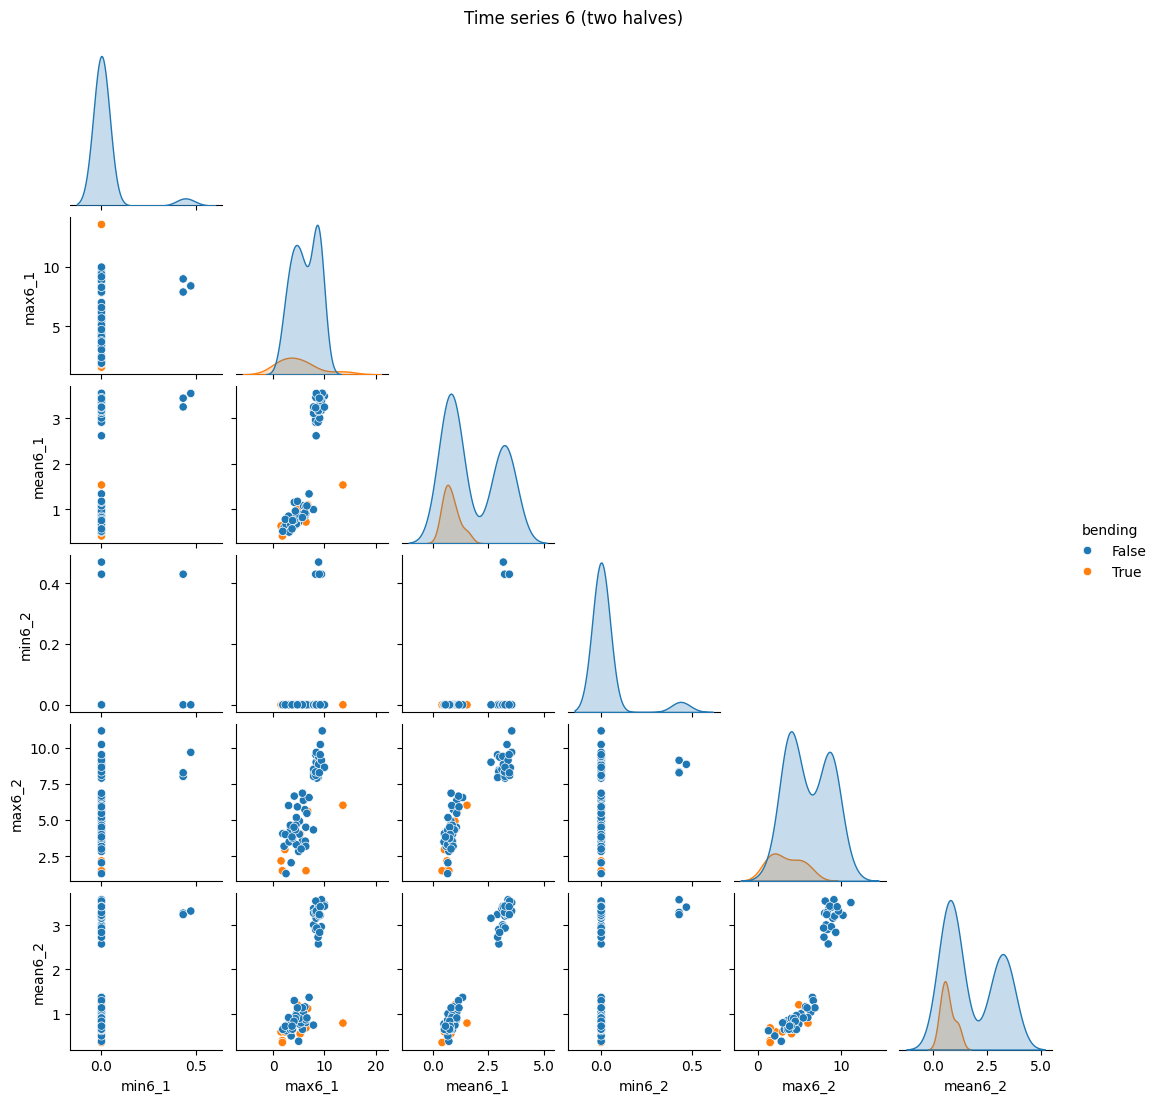

In [25]:
X2 = extract_features(train_files, 2)
for i in (1, 2, 6):
    g = sns.pairplot(X2[[f"{s}{i}_{h}" for h in (1, 2) for s in ("min", "max", "mean")]].assign(bending=y_train == 1),
                     hue="bending", corner=True, height=1.8)
    g.figure.suptitle(f"Time series {i} (two halves)", y=1.02)
plt.show()


No considerable difference. The features from each half are distributed much like the features from the full series, and bending is still clearly separated from the other activities.

#### iii. Time Series Segments

In [26]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rfecvs = {l: RFECV(make_pipeline(StandardScaler(), LogisticRegression(C=1e6, max_iter=100)), cv=skf, n_jobs=-1,
                   importance_getter="named_steps.logisticregression.coef_").fit(extract_features(train_files, l), y_train)
          for l in range(1, 21)}
cv_results = pd.DataFrame({"p": [r.n_features_ for r in rfecvs.values()],
                           "cv_accuracy": [r.cv_results_["mean_test_score"].max() for r in rfecvs.values()]},
                          index=pd.Index(rfecvs, name="l"))
best_l = cv_results["cv_accuracy"].idxmax()
cv_results


,p,cv_accuracy
l,,
1,8,0.985714
2,7,0.971429
3,4,0.942857
4,15,0.957143
5,11,0.956044
6,41,0.971429
7,7,0.942857
8,14,0.942857
9,4,0.941758


In [27]:
max_acc = cv_results["cv_accuracy"].max()
best_rows = cv_results[cv_results["cv_accuracy"] == max_acc]
best_rows

,p,cv_accuracy
l,,
1,8,0.985714
10,18,0.985714
19,11,0.985714
20,10,0.985714


I used 5-fold stratified cross-validation to select the number of segments l and the number of features p. Feature selection and standardization were performed within each cross-validation fold to avoid information leakage. Selecting features or scaling the data using the entire training set before cross-validation would produce an overly optimistic score. The highest mean cross-validation accuracy was 0.985714. This score was achieved by four combinations. I selected l=1 and p=8, the simplest of the tied combinations.

Stratified K-fold keeps the class proportions in every fold equal to those of the whole training set. This matters here because only 9 of the 69 training instances are bending. Following the alternative allowed in the assignment, I used backward selection (RFECV) instead of p-value pruning.

#### iv. Confusion Matrix

,Coef.,Std.Err.,P>|z|
const,-20.361882,930.951436,0.982550
3rd quart1,-5.434129,215.322054,0.979866
3rd quart3,-1.883371,362.486072,0.995854
max4,1.049029,539.672279,0.998449
1st quart4,-3.463470,2016.110857,0.998629
min5,6.765059,630.897615,0.991445
max5,9.033593,620.615693,0.988387
mean5,5.598320,1478.989719,0.996980
1st quart6,-4.629986,2577.431949,0.998567


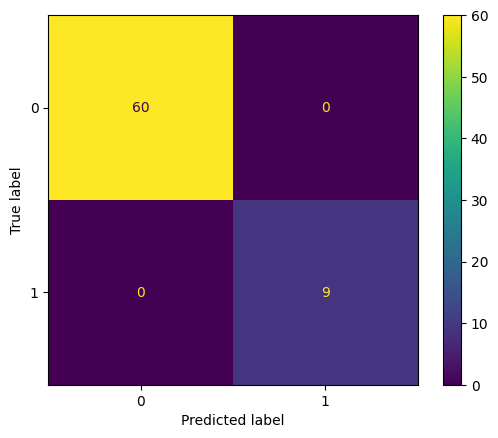

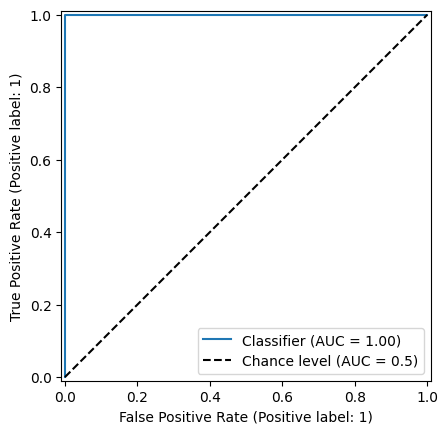

In [28]:
X_train, X_test = extract_features(train_files, best_l), extract_features(test_files, best_l)
selected = X_train.columns[rfecvs[best_l].support_]
scaler = StandardScaler().fit(X_train[selected])
design = lambda X: sm.add_constant(pd.DataFrame(scaler.transform(X[selected]), columns=selected))

logit = sm.Logit(y_train, design(X_train)).fit(method="bfgs", maxiter=100, disp=0)
display(logit.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]])
prob_train = logit.predict(design(X_train))
ConfusionMatrixDisplay.from_predictions(y_train, prob_train > 0.5)
RocCurveDisplay.from_predictions(y_train, prob_train, plot_chance_level=True)
plt.show()

#### v. Test Classifier

In [29]:
pred_test = logit.predict(design(X_test)) > 0.5
print(confusion_matrix(y_test, pred_test))
print(f"Test accuracy: {accuracy_score(y_test, pred_test):.3f}, CV accuracy: {cv_results.loc[best_l, 'cv_accuracy']:.3f}")


[[15  0]
 [ 0  4]]
Test accuracy: 1.000, CV accuracy: 0.986


The test accuracy (1.000) is close to the CV accuracy (0.986), so cross-validation gave a reliable estimate of out-of-sample performance.

#### vi. Separation

Yes. The classes appear to be almost linearly separable. The fitted coefficients have very large magnitudes and huge standard errors, and nearly all p-values are close to 1 (about 0.98–0.99). This is the classic sign of quasi-complete separation: the maximum likelihood estimates do not converge, so the p-values are no longer meaningful.

#### vii. Imbalance

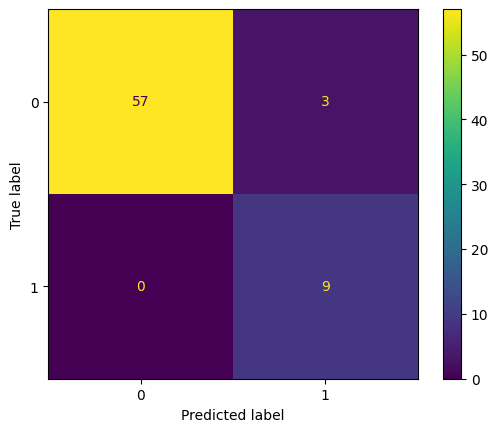

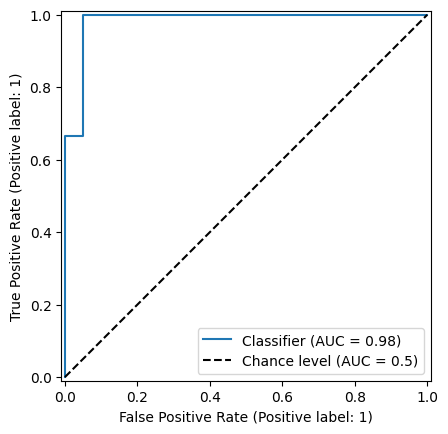

In [30]:
rng = np.random.default_rng(42)
cases = np.flatnonzero(y_train == 1)
idx = np.concatenate([cases, rng.choice(np.flatnonzero(y_train == 0), len(cases), replace=False)])
Z_train = design(X_train)
cc = sm.Logit(y_train[idx], Z_train.iloc[idx]).fit(method="bfgs", maxiter=100, disp=0)

pi, pi_tilde = y_train.mean(), 0.5
params = cc.params.copy()
params["const"] += np.log(pi / (1 - pi)) - np.log(pi_tilde / (1 - pi_tilde))
prob_cc = 1 / (1 + np.exp(-Z_train @ params))
ConfusionMatrixDisplay.from_predictions(y_train, prob_cc > 0.5)
RocCurveDisplay.from_predictions(y_train, prob_cc, plot_chance_level=True)
plt.show()

Yes. The confusion matrix shows imbalanced classes: the training set contains 60 non bending instances and 9 bending instances. I used case-control sampling, retaining all 9 bending cases and randomly selecting 9 non-bending controls. I then adjusted the model intercept to account for the original class prevalence. Evaluated on the full training set, the adjusted model produced the confusion matrix [57 3 0 9] and an ROC AUC of 0.98.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [31]:
def search_l(estimator, param_grid, y):
    searches = {l: GridSearchCV(estimator, param_grid, cv=skf, n_jobs=-1).fit(extract_features(train_files, l), y)
                for l in range(1, 21)}
    summary = pd.DataFrame([{**s.best_params_, "cv_accuracy": s.best_score_} for s in searches.values()],
                           index=pd.Index(searches, name="l"))
    best = summary["cv_accuracy"].idxmax()
    return best, searches[best].best_estimator_, summary

l1_l, l1_model, l1_summary = search_l(
    make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear")),
    {"logisticregression__C": np.logspace(-3, 3, 13)}, y_train)
pred = l1_model.predict(extract_features(test_files, l1_l))
print(f"best l = {l1_l}, test accuracy = {accuracy_score(y_test, pred):.3f}")
print(confusion_matrix(y_test, pred))
l1_summary

best l = 19, test accuracy = 0.947
[[15  0]
 [ 1  3]]


,logisticregression__C,cv_accuracy
l,,
1,1.000000,0.957143
2,1.000000,0.957143
3,0.316228,0.971429
4,1.000000,0.957143
5,3.162278,0.941758
6,3.162278,0.957143
7,0.316228,0.927473
8,1.000000,0.928571
9,0.316228,0.927473


Five-fold cross-validation selected l=19 and C=1.0, with a mean cross-validation accuracy of 0.9857. On the test set, the L1-penalized logistic regression model achieved an accuracy of 0.947 (test error = 0.053). The confusion matrix was [[15  0]
 [ 1  3]], indicating that one bending instance was classified as non-bending.

#### ii. Comparison

Both methods achieved a similar cross-validation accuracy (0.986). The L1-penalized model produced more stable coefficient estimates by discouraging the coefficients from becoming extremely large. In contrast, the unpenalized logistic regression refit using RFECV-selected features showed signs of quasi-complete separation, with very large coefficients and standard errors and unreliable p-values. The RFECV-based model had a higher test accuracy (1.000 vs. 0.947), although the difference was only one test instance. L1 regularization was easier to implement than RFECV-based feature selection, because a single GridSearchCV over C for each l handled selection and fitting together, with no separate elimination loop or p-value calculation.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

best l = 1, CV accuracy = 0.900, test error = 0.105


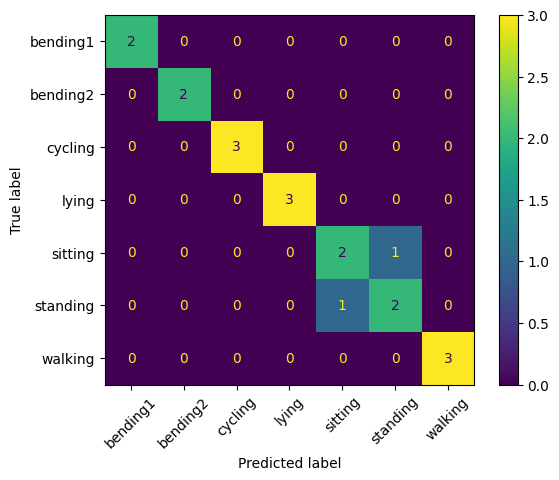

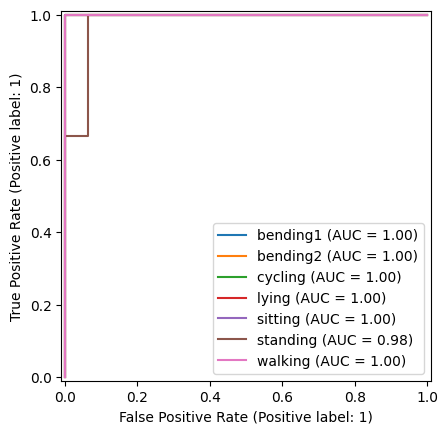

In [32]:
ym_train, ym_test = train_files["activity"].to_numpy(), test_files["activity"].to_numpy()
mn_l, mn_model, mn_summary = search_l(
    make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="saga", max_iter=5000)),
    {"logisticregression__C": np.logspace(-2, 3, 6)}, ym_train)
X_test_mn = extract_features(test_files, mn_l)
pred = mn_model.predict(X_test_mn)
print(f"best l = {mn_l}, CV accuracy = {mn_summary['cv_accuracy'].max():.3f}, test error = {1 - accuracy_score(ym_test, pred):.3f}")
ConfusionMatrixDisplay.from_predictions(ym_test, pred, xticks_rotation=45)

prob = mn_model.predict_proba(X_test_mn)
fig, ax = plt.subplots()
for k, c in enumerate(mn_model.classes_):
    RocCurveDisplay.from_predictions(ym_test == c, prob[:, k], name=c, ax=ax)
plt.show()

For K classes, the confusion matrix is a K×K table whose (i, j) entry counts instances of true class i predicted as class j. ROC curves are computed one-vs-rest: each class in turn is treated as positive and all others as negative, giving one ROC curve and AUC per class.

Stratified cross-validation selected l=1. The test error was 0.105, with 2 of 19 test instances misclassified. Both errors occurred between sitting and standing: one sitting instance was classified as standing, and one standing instance was classified as sitting. The one-vs-rest ROC AUC was 1.00 for all classes except standing, which had an AUC of 0.98. The test set is small, so these performance estimates should be interpreted cautiously.

#### ii. Naive Bayes

Gaussian NB: best l = 1, CV accuracy = 0.857, test error = 0.105


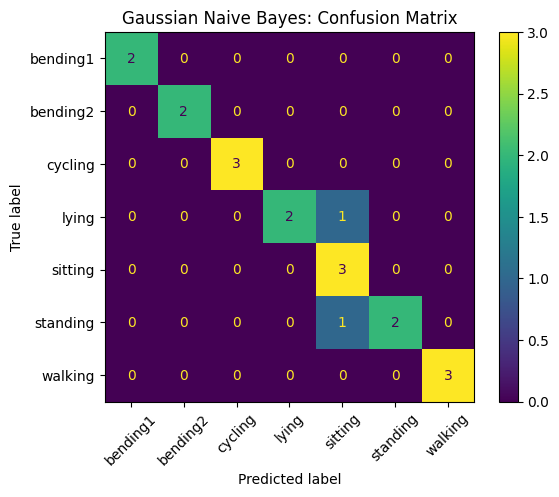

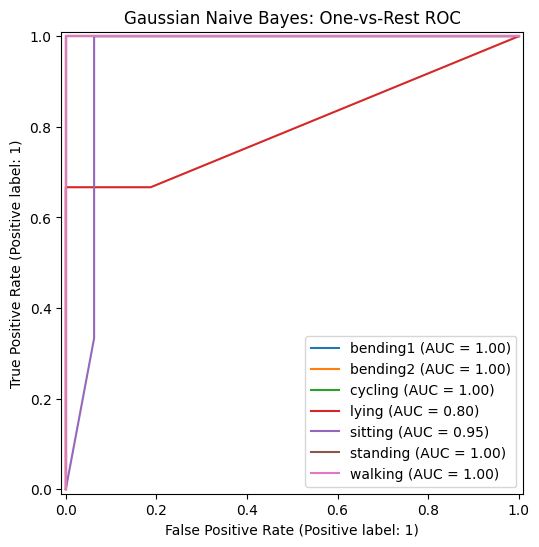

Multinomial NB: best l = 5, CV accuracy = 0.770, test error = 0.211


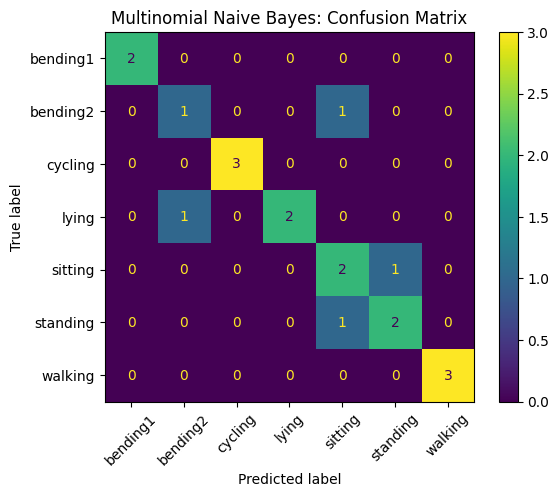

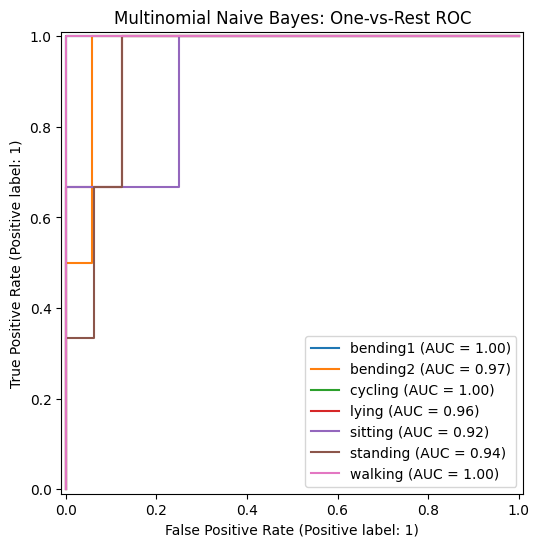

In [33]:
nb_results = {}

nb_models = {
    "Gaussian": GaussianNB(),
    "Multinomial": make_pipeline(MinMaxScaler(), MultinomialNB())
}

for name, model in nb_models.items():
    nb_l, nb_model, nb_summary = search_l(model, {}, ym_train)

    X_nb_test = extract_features(test_files, nb_l)
    pred = nb_model.predict(X_nb_test)
    prob = nb_model.predict_proba(X_nb_test)

    cv_accuracy = nb_summary.loc[nb_l, "cv_accuracy"]
    test_error = 1 - accuracy_score(ym_test, pred)

    nb_results[name] = {
        "l": nb_l,
        "model": nb_model,
        "cv_accuracy": cv_accuracy,
        "test_error": test_error,
        "predictions": pred
    }

    print(
        f"{name} NB: best l = {nb_l}, "
        f"CV accuracy = {cv_accuracy:.3f}, "
        f"test error = {test_error:.3f}"
    )

    ConfusionMatrixDisplay.from_predictions(
        ym_test, pred, xticks_rotation=45
    )
    plt.title(f"{name} Naive Bayes: Confusion Matrix")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 6))
    for k, c in enumerate(nb_model.classes_):
        RocCurveDisplay.from_predictions(
            ym_test == c,
            prob[:, k],
            name=c,
            ax=ax
        )
    ax.set_title(f"{name} Naive Bayes: One-vs-Rest ROC")
    plt.show()

Gaussian Naive Bayes outperformed Multinomial Naive Bayes in this experiment. Cross-validation selected \(l=1\) for Gaussian NB, with a CV accuracy of 0.857 and a test error of 0.105. For Multinomial NB, it selected \(l=5\), with a CV accuracy of 0.770 and a test error of 0.211. Gaussian NB misclassified two test instances, while Multinomial NB misclassified four. Although all extracted features were non-negative, they are continuous summary statistics rather than natural counts, so they may be less suitable for Multinomial NB. The results suggest that Gaussian NB was more appropriate for these features on this data split.

#### iii. Comparison

L1-penalized multinomial logistic regression is the better method for this problem. It and Gaussian NB have the same test error (0.105, 2 of 19 misclassified), but logistic regression has the higher cross-validation accuracy (0.900 vs. 0.857), and Multinomial NB is clearly the worst (CV accuracy 0.770, test error 0.211). Logistic regression's two errors are only between the similar static postures sitting and standing, and its one-vs-rest AUCs are almost all 1.00. With only 19 test instances, a single error changes the test error by about 5%, so the CV accuracy is the more reliable basis for comparison. Logistic regression also does not assume the features are independent, and the L1 penalty selects among the highly correlated features, whereas Naive Bayes relies on that independence assumption.

## 3. ISLR 4.8.3

For class $k$, the conditional distribution is $X\mid Y=k\sim\mathcal{N}(\mu_k,\sigma_k^2)$, and let $\pi_k=P(Y=k)$. By Bayes' rule, the Bayes classifier assigns $x$ to the class with the largest value of $\pi_k f_k(x)$. Taking logarithms and dropping the constant shared by all classes, the discriminant score for class $k$ is

$$
\delta_k(x)
=
\log(\pi_k)
-\frac{1}{2}\log(\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac{1}{2}\log(\sigma_k^2)
+\log(\pi_k).
$$

Thus, each class has a quadratic discriminant score, and the classifier assigns $x$ to the class with the largest score. The boundary between classes $k$ and $j$ is obtained by setting $\delta_k(x)=\delta_j(x)$. If $\sigma_k^2\ne\sigma_j^2$, the coefficient of $x^2$ in this equation is nonzero, so the boundary is quadratic rather than linear. Therefore, without assuming equal class variances, the Bayes classifier is in general quadratic.

## 4. ISLR 4.8.7

Let $Y=\text{Yes}$ denote that a company issues a dividend and $Y=\text{No}$ otherwise. The prior probabilities are $P(Y=\text{Yes})=0.8$ and $P(Y=\text{No})=0.2$. The class-conditional distributions are

$$
X\mid Y=\text{Yes}\sim\mathcal{N}(10,36),
\qquad
X\mid Y=\text{No}\sim\mathcal{N}(0,36).
$$

Using Bayes' theorem, the posterior probability that a company issues a dividend when $X=4$ is

$$
\begin{aligned}
P(Y=\text{Yes}\mid X=4)
&=
\frac{0.8 f_{\text{Yes}}(4)}
{0.8 f_{\text{Yes}}(4)+0.2 f_{\text{No}}(4)}\\
&=
\frac{0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)}
{0.8\exp\left(-\frac{(4-10)^2}{2(36)}\right)
+0.2\exp\left(-\frac{(4-0)^2}{2(36)}\right)}\\
&\approx 0.752.
\end{aligned}
$$

Therefore, the posterior probability that the company issues a dividend is approximately $75.2\%$.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9